Số lượng mẫu huấn luyện (Train): 72, Tập kiểm thử (Test): 18

1. Logistic Regression -> Best Train Accuracy: 0.8464 | Test Accuracy: 0.8333
2. Support Vector Machine -> Best Train Accuracy: 0.8482 | Test Accuracy: 0.8333


C:\Anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
3240 fits failed out of a total of 6480.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
3240 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Anaconda3\Lib\site-packages\sklearn\base.py", line 1358, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "C:\Anaconda3\Lib\site-packages\sklearn\base.py", line 471, in _validate_params
    validate_parameter_constraints(
    ~~~~~~

3. Decision Tree -> Best Train Accuracy: 0.8768 | Test Accuracy: 0.8333
4. K-Nearest Neighbors -> Best Train Accuracy: 0.8482 | Test Accuracy: 0.8333

==================== BẢNG SO SÁNH KẾT QUẢ MÔ HÌNH ====================
                 Model  Train Accuracy  Test Accuracy
0  Logistic Regression        0.846429       0.833333
1                  SVM        0.848214       0.833333
2        Decision Tree        0.876786       0.833333
3                  KNN        0.848214       0.833333


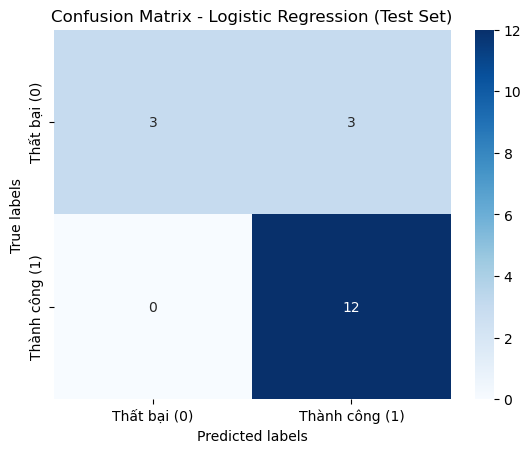

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score


def plot_confusion_matrix(y, y_predict, title="Confusion Matrix"):
    cm = confusion_matrix(y, y_predict)
    ax = plt.subplot()
    sns.heatmap(cm, annot=True, ax=ax, cmap="Blues", fmt="g")
    ax.set_xlabel('Predicted labels')
    ax.set_ylabel('True labels')
    ax.set_title(title)
    ax.xaxis.set_ticklabels(['Thất bại (0)', 'Thành công (1)'])
    ax.yaxis.set_ticklabels(['Thất bại (0)', 'Thành công (1)'])
    plt.show()


X = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_3.csv')
Y = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv')['Class'].to_numpy()


transform = preprocessing.StandardScaler()
X = transform.fit_transform(X)


X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
print(f"Số lượng mẫu huấn luyện (Train): {X_train.shape[0]}, Tập kiểm thử (Test): {X_test.shape[0]}")


parameters_lr = {"C": [0.01, 0.1, 1], "penalty": ["l2"], "solver": ["lbfgs"]}
lr = LogisticRegression()
logreg_cv = GridSearchCV(lr, parameters_lr, cv=10)
logreg_cv.fit(X_train, Y_train)

acc_lr_train = logreg_cv.best_score_
acc_lr_test = logreg_cv.score(X_test, Y_test)
print(f"\n1. Logistic Regression -> Best Train Accuracy: {acc_lr_train:.4f} | Test Accuracy: {acc_lr_test:.4f}")


parameters_svm = {'kernel': ('linear', 'rbf', 'poly', 'sigmoid'),
                  'C': np.logspace(-3, 3, 5),
                  'gamma': np.logspace(-3, 3, 5)}
svm = SVC()
svm_cv = GridSearchCV(svm, parameters_svm, cv=10)
svm_cv.fit(X_train, Y_train)

acc_svm_train = svm_cv.best_score_
acc_svm_test = svm_cv.score(X_test, Y_test)
print(f"2. Support Vector Machine -> Best Train Accuracy: {acc_svm_train:.4f} | Test Accuracy: {acc_svm_test:.4f}")


parameters_tree = {'criterion': ['gini', 'entropy'],
                   'splitter': ['best', 'random'],
                   'max_depth': [2*n for n in range(1, 10)],
                   'max_features': ['auto', 'sqrt'],
                   'min_samples_leaf': [1, 2, 4],
                   'min_samples_split': [2, 5, 10]}
tree = DecisionTreeClassifier()
tree_cv = GridSearchCV(tree, parameters_tree, cv=10)
tree_cv.fit(X_train, Y_train)

acc_tree_train = tree_cv.best_score_
acc_tree_test = tree_cv.score(X_test, Y_test)
print(f"3. Decision Tree -> Best Train Accuracy: {acc_tree_train:.4f} | Test Accuracy: {acc_tree_test:.4f}")


parameters_knn = {'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                  'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
                  'p': [1, 2]}
knn = KNeighborsClassifier()
knn_cv = GridSearchCV(knn, parameters_knn, cv=10)
knn_cv.fit(X_train, Y_train)

acc_knn_train = knn_cv.best_score_
acc_knn_test = knn_cv.score(X_test, Y_test)
print(f"4. K-Nearest Neighbors -> Best Train Accuracy: {acc_knn_train:.4f} | Test Accuracy: {acc_knn_test:.4f}")


models_summary = pd.DataFrame({
    'Model': ['Logistic Regression', 'SVM', 'Decision Tree', 'KNN'],
    'Train Accuracy': [acc_lr_train, acc_svm_train, acc_tree_train, acc_knn_train],
    'Test Accuracy': [acc_lr_test, acc_svm_test, acc_tree_test, acc_knn_test]
})

print("\n==================== BẢNG SO SÁNH KẾT QUẢ MÔ HÌNH ====================")
print(models_summary)


yhat_lr = logreg_cv.predict(X_test)
plot_confusion_matrix(Y_test, yhat_lr, title="Confusion Matrix - Logistic Regression (Test Set)")